In [1]:
import os
# Keras backend: "tensorflow" (default) or "torch". Must be set before keras is imported.
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

'tensorflow'

In [3]:
import pandas as pd

# Enter here the Dataset ID that you have received in the spreadsheet.
# Make sure that you use the ID that was assigned to you,
# otherwise your submission will be graded against the wrong images.
dataset_id = '20261029-062502_c4806367139f99116fb0e9005efb1aea'

# Assignment datasets are stored in an AWS S3 bucket. The following code
# downloads your dataset (~60MB) directly into RAM. Optionally,
# you can save the datasets to the local disk, but that's really not required.
prefix = f's3://danylo-ucla/app/storage/mnist/jobs/transform_repack/{dataset_id}'

# The train dataframe contains only normal images: handwritten digits.
# Use it to train your model.
train_X = pd.read_parquet(f'{prefix}/train_x.parquet')

# In the validate and test dataframes, 75% of the images are anomalies
# (corrupted digits, or images that are not digits at all), and 25% are normal digits.
# Use them to select and evaluate your model, respectively.
validate_X = pd.read_parquet(f'{prefix}/validate_x.parquet')
test_X = pd.read_parquet(f'{prefix}/test_x.parquet')

# This is the segment of the dataset that will be graded in this assignment.
# It has the same mix of normal images and anomalies as validate and test, but no labels.
# Your model has to assign an anomaly score to each image, and you have to submit these scores.
score_X = pd.read_parquet(f'{prefix}/score_x.parquet')

# These are the labels corresponding to each image in the dataset.
# train_y has the digit of each image.
# validate_y and test_y have the following columns:
#   is_anomaly -- 1 if the image is an anomaly, 0 if it is a normal digit (this is what you predict)
#   anomaly_family, anomaly_type -- the kind of anomaly ('none' for normal images)
#   digit -- the digit that the image was made from (-1 if it is not a digit)
# Use the labels to select your model and to analyze which anomalies your model
# has more or less problems with. The labels should not be used to train the model itself:
# the model has to learn what normal images look like from the train dataframe only.
train_y = pd.read_parquet(f'{prefix}/train_y.parquet')
validate_y = pd.read_parquet(f'{prefix}/validate_y.parquet')
test_y = pd.read_parquet(f'{prefix}/test_y.parquet')

In [4]:
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

In [5]:
import numpy as np

# The share of anomalies in the validate dataframe,
# and how many images there are of each kind of anomaly.
print('Anomaly rate:', validate_y['is_anomaly'].mean())
validate_y.groupby(['anomaly_family', 'anomaly_type']).size()

Anomaly rate: 0.75


anomaly_family  anomaly_type  
geometric       elastic            337
                shear              315
                shift              358
                zoom               351
noise           gaussian_noise     324
                patch_noise        352
                salt_pepper        333
                speckle            373
none            none              1750
occlusion       cutout             241
                letter             311
                mashup             328
                strokes            317
photometric     background         228
                blur               205
                invert             223
                low_contrast       216
                thicken            211
                thin               227
dtype: int64

In [6]:
# Just as in the lecture slides, the input matrix
# has row vectors that hold pixels of a single 28x28 image.
# Note that the column vectors are individual locations on
# the 28x28 grid, but flattened in a row-major way (28x28=784).
train_X.shape

(49000, 784)

In [7]:
example_id = 1

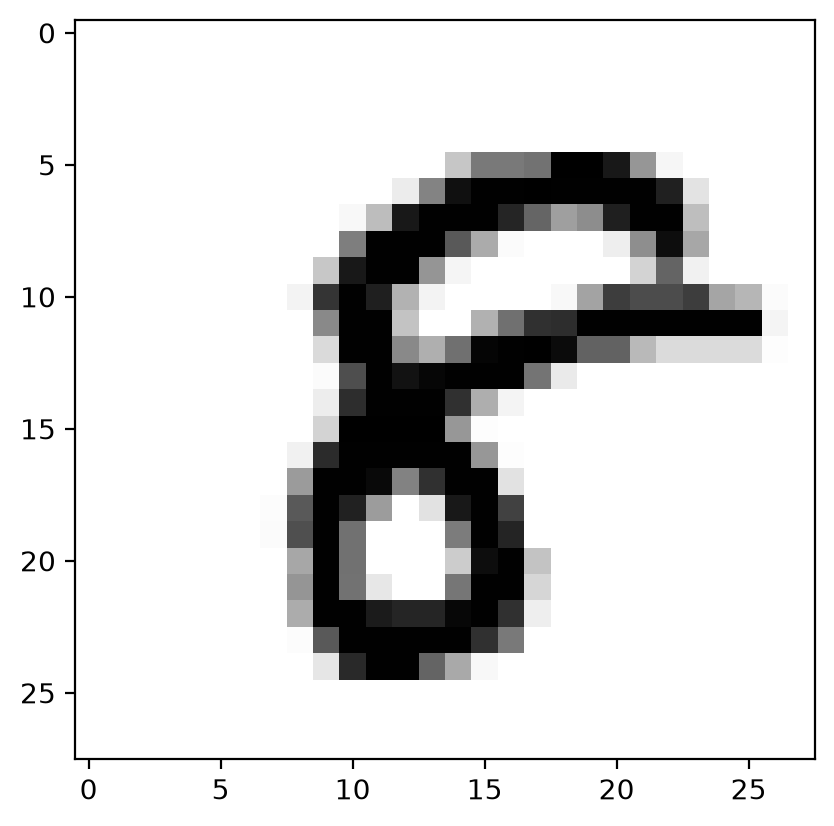

In [8]:
# Let's select a normal image from the train dataframe
image_pixels = train_X.iloc[example_id]

# In order to plot an image, you need to reshape
# the flattened array back into a 28x28 grid.
image_pixels = image_pixels.values.reshape(28, 28)

plt.imshow(image_pixels, cmap='binary')

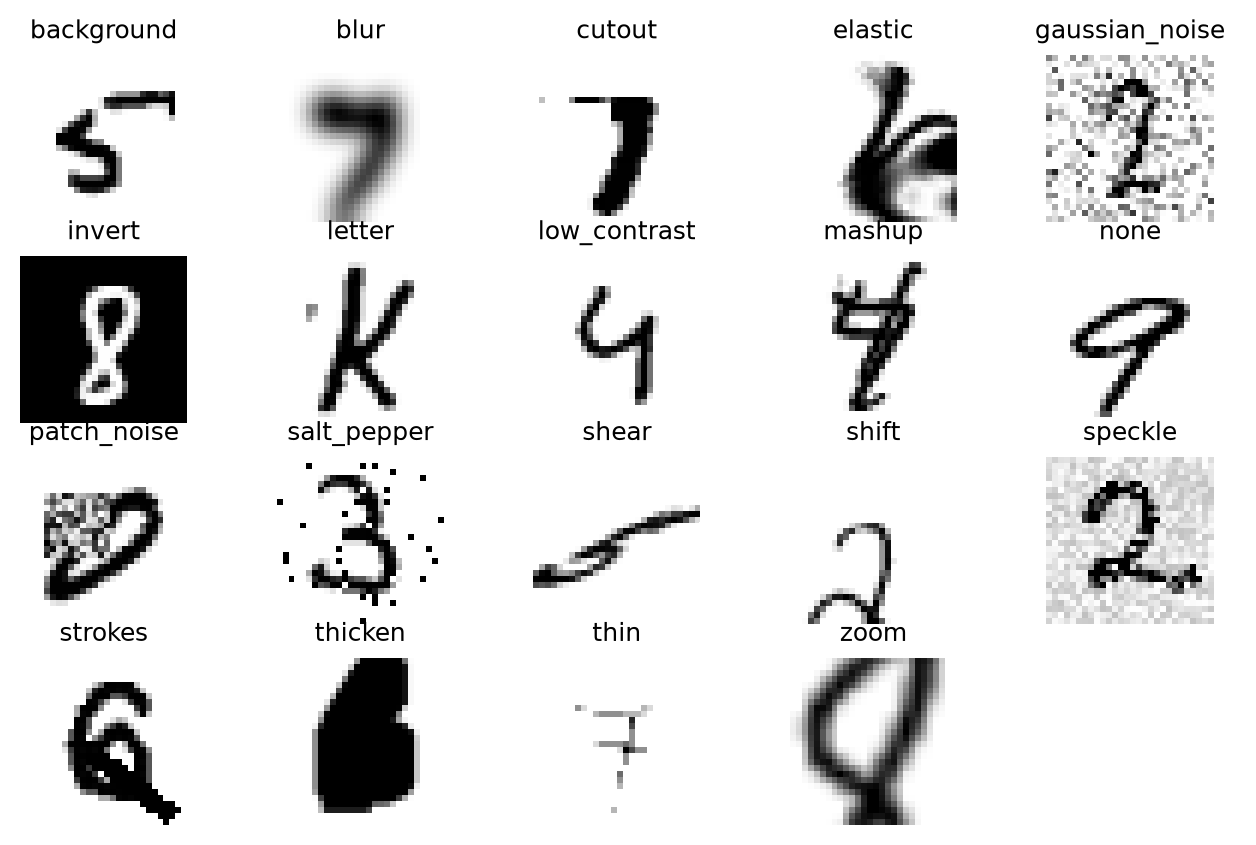

In [36]:
# Let's plot an example of each anomaly type from the validate dataframe.
anomaly_types = sorted(validate_y['anomaly_type'].unique())

fig, axes = plt.subplots(4, 5, figsize=(8, 5))
for ax in axes.flat:
    ax.axis('off')

for ax, anomaly_type in zip(axes.flat, anomaly_types):
    i = np.flatnonzero(validate_y['anomaly_type'] == anomaly_type)[0]
    ax.imshow(validate_X.iloc[i].values.reshape(28, 28), cmap='binary')
    ax.set_title(anomaly_type, fontsize=9)

plt.show()

In [10]:
train_y.iloc[example_id]

digit    8
Name: 1, dtype: int64

In [11]:
# Run this cell to check which Keras backend and GPU you are using.
import keras
print('Keras backend:', keras.backend.backend())

if keras.backend.backend() == 'tensorflow':
    import tensorflow as tf
    for gpu in tf.config.list_physical_devices('GPU'):
        print(gpu)
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    import torch
    print('PyTorch device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')

I0000 00:00:1793637511.234719 2757600 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Keras backend: tensorflow
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:2', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:3', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:4', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:5', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:6', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:7', device_type='GPU')


In [ ]:
# The assignment template is using Keras library.
# https://keras.io

import mlflow
import keras
from keras.layers import Input, Dense
from keras.models import Sequential
from keras import optimizers


def build_model(encoder_width: int, learning_rate_log: float) -> keras.Model:
    mlflow.log_param('encoder_width', encoder_width)
    mlflow.log_param('learning_rate_log', learning_rate_log)
    
    # IMPORTANT: This is an example of a very simple undercomplete autoencoder.
    # In other words, you will probably need to tweak these lines of code.
    
    layers = [
        # Input: a flattened 28x28 image
        Input(shape=(28 * 28,)),

        # Encoder: Gaussian Error Linear Unit activation
        Dense(
            units=encoder_width, 
            activation='gelu', 
        ),

        # Decoder: matches the shape of the image
        # Sigmoid activation is needed because pixel
        # values are real numbers between 0 (dark) and 1 (bright).
        Dense(units=28*28, activation='sigmoid')
    ]

    # Sequential class is a Keras class that attaches every 
    # layer's output to the next layer's input.
    # This is essentially a helper class for any feedforward networks.
    autoencoder = Sequential(layers)

    # Using MSE as the loss function, and Adam optimizer.
    # Other optimizers can also be used.
    autoencoder.compile(
        optimizer=optimizers.Adam(
            learning_rate=float(10 ** learning_rate_log),
        ), 
        loss='mean_squared_error',
    )
    return autoencoder

In [25]:
import json
import uuid
import os

# This function will be used to save each trained model.
def save_model(model: keras.Model, model_path: str):
    os.makedirs(model_path, exist_ok=True)
    model.save(f'{model_path}/model.keras')
    with open(f'{model_path}/architecture.json', 'w') as f:
        f.write(model.to_json(indent=True))


# This function can be used to load a previously trained model.
def load_model(model_path: str) -> keras.Model:
    return keras.models.load_model(f'{model_path}/model.keras')

In [ ]:
from collegium.foundation.callbacks import MlflowCallback
from sklearn.metrics import roc_auc_score
import tempfile

# The validation loss is measured on the normal images of the validate dataframe.
validate_normal_X = validate_X[validate_y['is_anomaly'] == 0]


# The anomaly score of each image: the higher, the more likely the image is an anomaly.
def anomaly_score(model: keras.Model, X: pd.DataFrame) -> np.ndarray:
    reconstructed_X = model.predict(X, verbose=0)
    return ((np.asarray(X) - reconstructed_X) ** 2).sum(axis=1)


def train_anomaly_model(model: keras.Model, epochs: int, verbose: int = 10) -> keras.callbacks.History:
    history = model.fit(
        x=train_X,
        y=train_X,

        # It's a good idea to have low number of epochs,
        # to test the learning process, but not for the final model training.
        epochs=epochs,

        batch_size=128,
        shuffle=True,
        validation_data=(validate_normal_X, validate_normal_X),
        callbacks=[MlflowCallback()],
        verbose=verbose
    )

    # Marks the run as a Keras model (the PyTorch variant of this notebook may log to the same experiment).
    mlflow.set_tag('framework', 'keras')

    # ROC AUC measures how well the anomaly scores separate anomalies from normal images:
    # 1.0 is perfect separation, 0.5 is random guessing. This is the graded metric.
    mlflow.log_metric('validate_auc', roc_auc_score(validate_y['is_anomaly'], anomaly_score(model, validate_X)))

    # Save model parameters to the file system and upload to MLFlow.
    with tempfile.TemporaryDirectory('wb') as d:
        model_path = f'{d}/model'
        save_model(model, model_path)
        mlflow.log_artifacts(d)

    return history

In [15]:
# See MLFlow docs for more API examples.
# https://mlflow.org/docs/latest/python_api/mlflow.html

import mlflow
mlflow.set_experiment('assignment_01')
# mlflow.tensorflow.autolog(log_models=False, log_input_examples=False, log_model_signatures=False, silent=True)

<Experiment: artifact_location='/home/ubuntu/git/ucla-deeplearning/m01_dnn/mlruns/1', creation_time=1792881782121, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792881782121, lifecycle_stage='active', name='assignment_01', tags={}, trace_location=None, workspace='default'>

In [16]:
mlflow.get_experiment_by_name('assignment_01')

<Experiment: artifact_location='/home/ubuntu/git/ucla-deeplearning/m01_dnn/mlruns/1', creation_time=1792881782121, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792881782121, lifecycle_stage='active', name='assignment_01', tags={}, trace_location=None, workspace='default'>

In [26]:
# In order to have reproducible results, we need
# to set the seed values for Python, NumPy, and the Keras backend.
# Keep these lines in the same cell as the training code,
# so that you don't accidentally train multiples models
# without reseting the seed.

import keras

keras.utils.set_random_seed(11)

with mlflow.start_run():
    autoencoder = build_model(encoder_width=10, learning_rate_log=0)
    history = train_anomaly_model(autoencoder, epochs=10)

Epoch 1/10


I0000 00:00:1793637897.984335 2758274 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_169586__.5
I0000 00:00:1793637899.113680 2758273 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_169586__.5


Epoch 2/10
Epoch 3/10
Epoch 4/10
Epoch 5/10
Epoch 6/10
Epoch 7/10
Epoch 8/10
Epoch 9/10
Epoch 10/10


In [27]:
validate_scores = anomaly_score(autoencoder, validate_X)
roc_auc_score(validate_y['is_anomaly'], validate_scores)

0.641925768707483

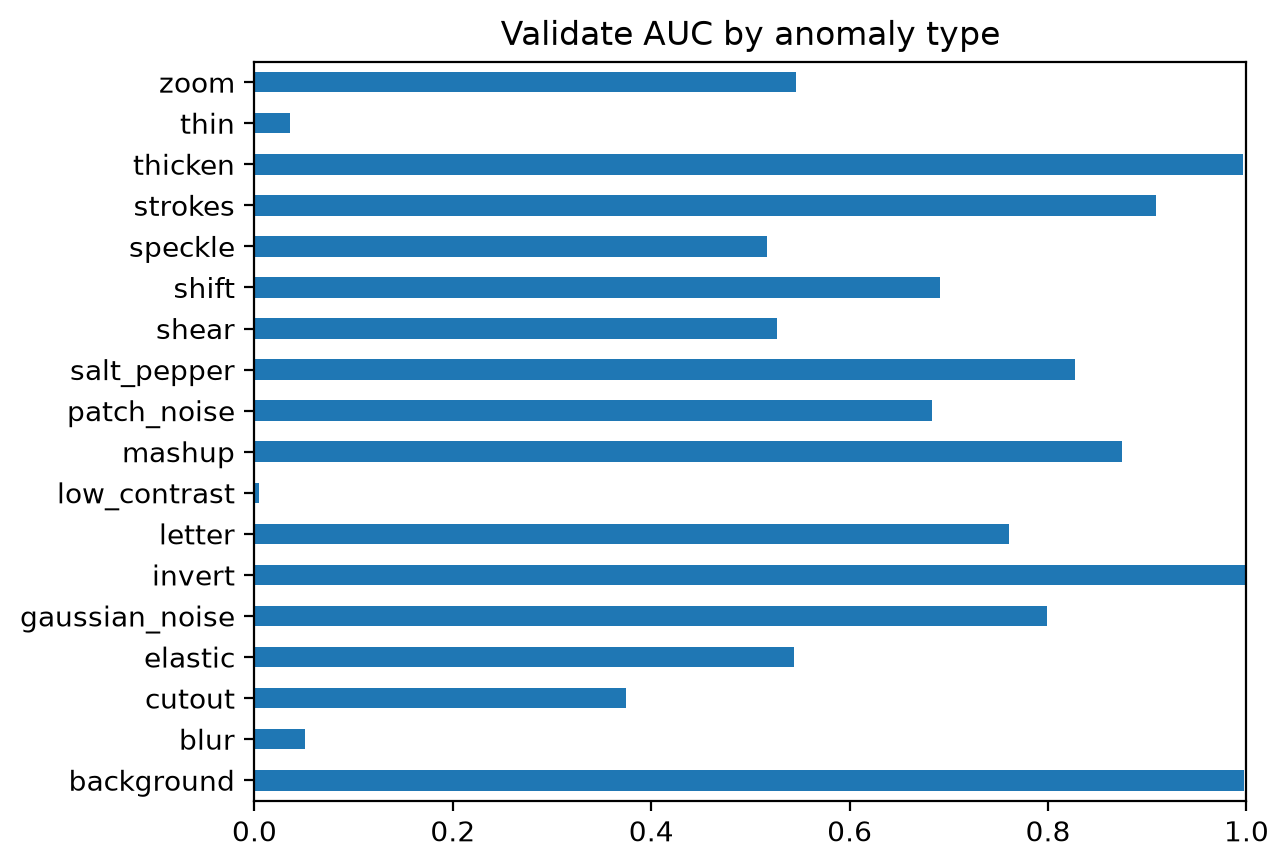

In [19]:
# The AUC of each anomaly type: images of that anomaly type against all normal images.
# This shows which anomalies the model detects well, and which ones it misses.
# An AUC of 0.5 is no better than random guessing, and an AUC below 0.5 means
# that the model scores these anomalies as *more normal* than the normal images.
def auc_by_anomaly_type(y: pd.DataFrame, scores: np.ndarray) -> pd.Series:
    normal = (y['is_anomaly'] == 0).values
    result = {}
    for anomaly_type in sorted(y.loc[~normal, 'anomaly_type'].unique()):
        mask = normal | (y['anomaly_type'] == anomaly_type).values
        result[anomaly_type] = roc_auc_score(y['is_anomaly'][mask], scores[mask])
    return pd.Series(result)

auc_by_anomaly_type(validate_y, validate_scores).plot.barh(title='Validate AUC by anomaly type', xlim=(0, 1))
plt.show()

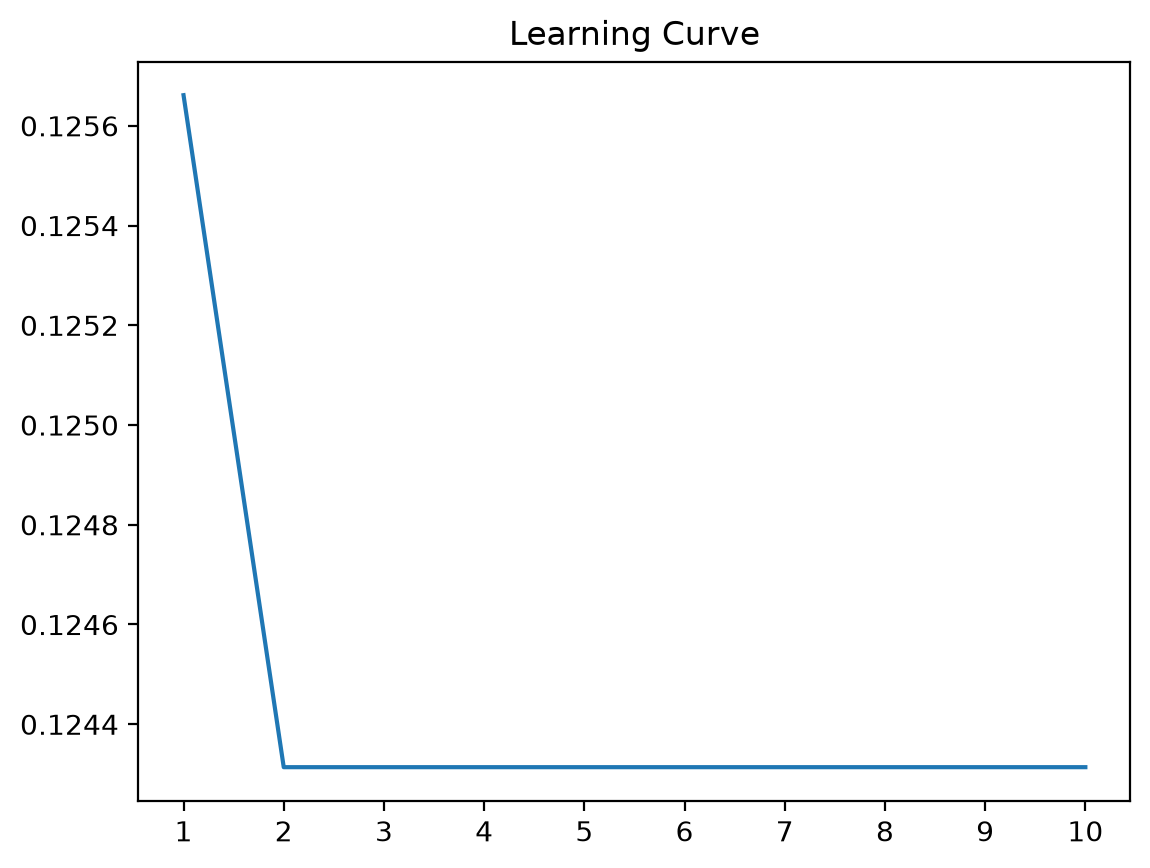

In [20]:
# The fit method returns a history object that
# can be used to plot the learning curve.

learning_curve = pd.Series(history.history['loss'])
learning_curve.index = learning_curve.index + 1

learning_curve.plot(title='Learning Curve')
plt.xticks(learning_curve.index)
plt.show()

In [21]:
import random
import tqdm
import warnings

runs = 10
learning_rate_logs = [random.uniform(-5, 0) for _ in range(runs)]
encoder_widths = [random.choice(range(5, 20, 5)) for _ in range(runs)]
parameters = list(zip(learning_rate_logs, encoder_widths))

for (learning_rate_log, encoder_width) in tqdm.tqdm(parameters):
    with mlflow.start_run():
        autoencoder = build_model(encoder_width=encoder_width, learning_rate_log=learning_rate_log)
        history = train_anomaly_model(autoencoder, epochs=10, verbose=0)

  0%|          | 0/10 [00:00<?, ?it/s]I0000 00:00:1793637537.031488 2758277 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_17409__.5
I0000 00:00:1793637539.533838 2758277 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_17409__.5
I0000 00:00:1793637542.344222 2764176 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_4', 8 bytes spill stores, 8 bytes spill loads

 10%|█         | 1/10 [00:15<02:20, 15.64s/it]I0000 00:00:1793637552.631713 2758274 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_32284__.5
I0000 00:00:1793637553.870854 2758277 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_32284__.5
 20%|██        | 2/10 [00:28<01:49, 13.72s/it]I0000 00:00:1793637565.015560 2758276 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_47159__.5
I0000 00:00:1793637568.036625 2758274 dot_m

In [22]:
# This loads the run with the best validate AUC in the experiment (among the runs of this notebook).
best_run = mlflow.search_runs(filter_string="tags.framework = 'keras'", order_by=['metrics.validate_auc DESC'], max_results=1).iloc[0]
print('Best run:', best_run['run_id'], 'validate AUC:', best_run['metrics.validate_auc'])
saved_model_path = mlflow.tracking.MlflowClient().download_artifacts(best_run['run_id'], 'model')
autoencoder = load_model(saved_model_path)

Best run: 9c1fdfc46f844462b1349788d3cb06bf validate AUC: 0.8236705850340136


In [23]:
# Once you have selected the final model on the validate dataframe,
# measure its performance on the test dataframe, which was not used to select it.
# Don't let a model that overfits the validate dataframe fool you into using it for the graded submission!
test_scores = anomaly_score(autoencoder, test_X)
roc_auc_score(test_y['is_anomaly'], test_scores)

0.8198881632653061

In [28]:
import os

model_path = 'assignment_submission'

os.makedirs(model_path, exist_ok=True)

# Once you are ready to make the graded submission,
# calculate the anomaly scores of the score dataframe.
# Higher score means more likely to be an anomaly, and the rows must stay in the same order as score_X.
score_anomaly_score = pd.DataFrame({'anomaly_score': anomaly_score(autoencoder, score_X)})

# Now save it to disc as a Parquet file.
score_anomaly_score.to_parquet(f'{model_path}/score_anomaly_score.parquet')

save_model(autoencoder, model_path)

# You now have the following files to be uploaded:
# 1. This notebook and any other Python code you used to train the final model.
# 2. architecture.json -- the model's definition
# 3. model.keras -- the model's trained parameters
# 4. score_anomaly_score.parquet - the model's anomaly scores on the score dataset